### Imports e Carregamento do Pipeline

In [5]:
from __future__ import annotations

from pathlib import Path
import sys

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

MODEL_PATH = PROJECT_ROOT / "models" / "bbc_multinomial_pipeline.joblib"

if not MODEL_PATH.exists():
    raise FileNotFoundError(f"Modelo não encontrado em: {MODEL_PATH}. Execute src/train.ipynb primeiro!")

pipeline = joblib.load(MODEL_PATH)
classes = list(pipeline.classes_)

print(f"Pipeline carregado com sucesso de: {MODEL_PATH}")
print(f"Classes suportadas: {classes}")


Pipeline carregado com sucesso de: c:\Users\diego\Desktop\repositorios\bayes-bbc-prediction\models\bbc_multinomial_pipeline.joblib
Classes suportadas: [np.str_('business'), np.str_('entertainment'), np.str_('politics'), np.str_('sport'), np.str_('tech')]


### Função auxiliar de Classificação e Formatação

In [6]:
def classificar_texto(texto: str) -> pd.DataFrame:
    """Classifica um texto em linguagem natural e retorna as probabilidades por classe."""
    pred_classe = pipeline.predict([texto])[0]
    probas = pipeline.predict_proba([texto])[0]
    
    df_res = pd.DataFrame({
        "Categoria": classes,
        "Probabilidade (%)": (probas * 100).round(2),
        "Probabilidade Bruta": probas,
    }).sort_values(by="Probabilidade Bruta", ascending=False).reset_index(drop=True)
    
    print("=" * 70)
    print(f"Texto Analisado: {texto[:100]}..." if len(texto) > 100 else f"Texto Analisado: {texto}")
    print(f"Classe Prevista: {pred_classe.upper()} (Confiança: {df_res.iloc[0]['Probabilidade (%)']}%)")
    print("=" * 70)
    
    return df_res


### Função de Visualização Gráfica de Confiança

In [7]:
def plotar_probabilidades(df_res: pd.DataFrame, titulo: str = "Distribuição de Probabilidades a Posteriori") -> None:
    """Plota um gráfico de barras horizontais com as probabilidades de cada classe."""
    plt.figure(figsize=(8, 4))
    
    paleta = ["#1f77b4" if i == 0 else "#aec7e8" for i in range(len(df_res))]
    bars = plt.barh(df_res["Categoria"][::-1], df_res["Probabilidade (%)"][::-1], color=paleta[::-1])
    
    plt.title(titulo, fontsize=13, weight="bold", pad=12)
    plt.xlabel("Probabilidade Estimada (%)", fontsize=11)
    plt.xlim(0, 105)
    
    for bar in bars:
        width = bar.get_width()
        plt.text(width + 1.5, bar.get_y() + bar.get_height() / 2, f"{width:.2f}%", ha="left", va="center", fontsize=10)
        
    plt.tight_layout()
    plt.show()


### Teste Interativo: Notícias do Mundo Real


>>> Testando Exemplo Esperado: BUSINESS
Texto Analisado: Wall Street shares rose sharply following Federal Reserve comments on interest rates cuts and strong...
Classe Prevista: BUSINESS (Confiança: 100.0%)


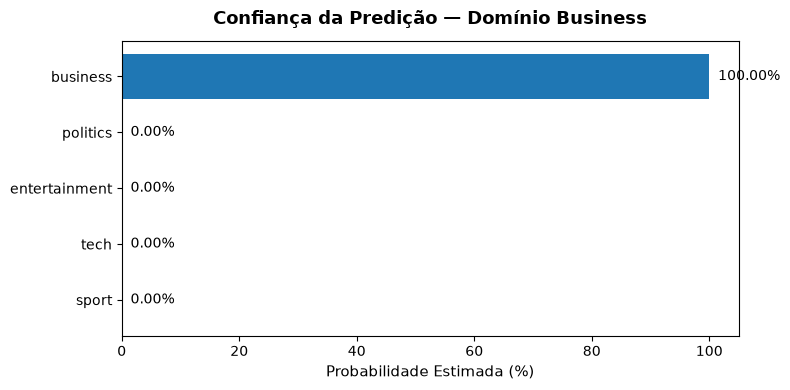


>>> Testando Exemplo Esperado: ENTERTAINMENT
Texto Analisado: The latest fantasy blockbuster scored record-breaking ticket sales at the international box office, ...
Classe Prevista: ENTERTAINMENT (Confiança: 100.0%)


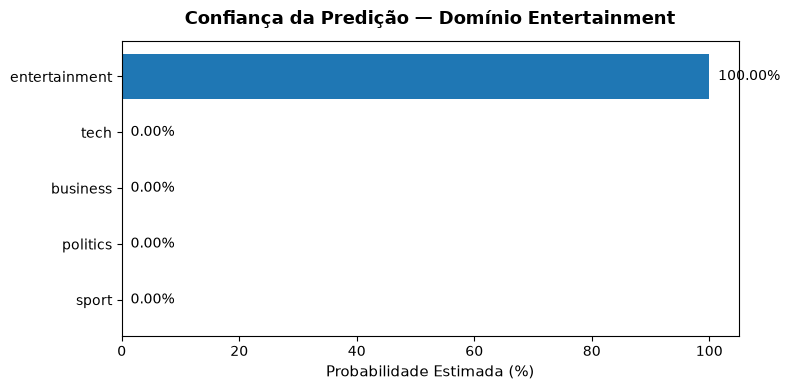


>>> Testando Exemplo Esperado: POLITICS
Texto Analisado: The Prime Minister faced intense scrutiny in Parliament as opposition MPs debated the government's e...
Classe Prevista: POLITICS (Confiança: 100.0%)


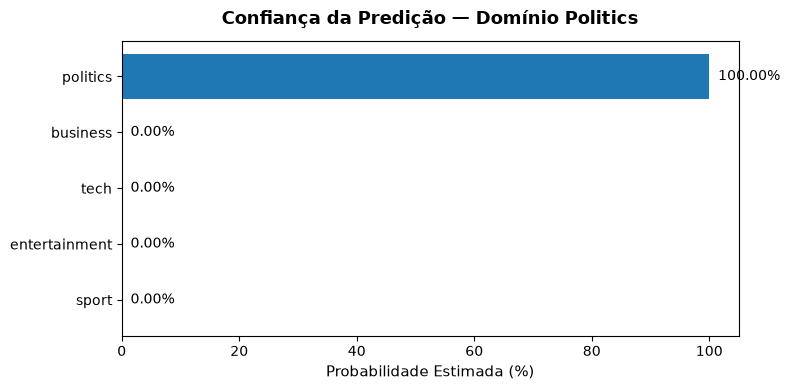


>>> Testando Exemplo Esperado: SPORT
Texto Analisado: Manchester United secured a dramatic 2-1 victory in the Champions League semifinal after scoring in ...
Classe Prevista: SPORT (Confiança: 100.0%)


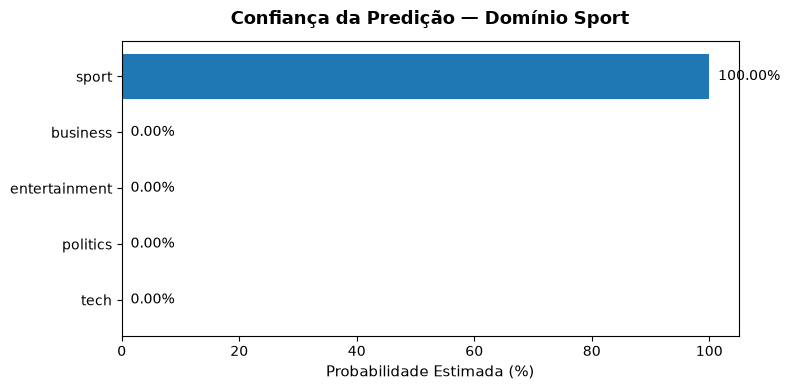


>>> Testando Exemplo Esperado: TECH
Texto Analisado: Tech giants unveil breakthrough generative artificial intelligence chip designed to accelerate deep ...
Classe Prevista: TECH (Confiança: 100.0%)


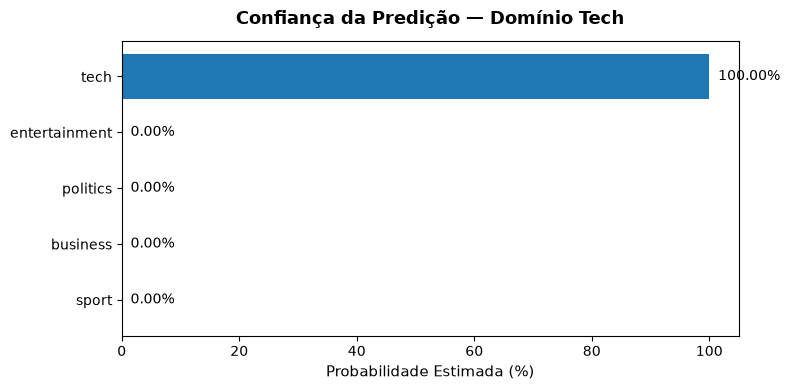

In [8]:
noticias_teste = {
    "Business": "Wall Street shares rose sharply following Federal Reserve comments on interest rates cuts and strong quarterly profits from banking corporations.",
    "Entertainment": "The latest fantasy blockbuster scored record-breaking ticket sales at the international box office, earning multiple nominations for best director and film.",
    "Politics": "The Prime Minister faced intense scrutiny in Parliament as opposition MPs debated the government's economic legislation ahead of next month's general election.",
    "Sport": "Manchester United secured a dramatic 2-1 victory in the Champions League semifinal after scoring in stoppage time against their league rivals.",
    "Tech": "Tech giants unveil breakthrough generative artificial intelligence chip designed to accelerate deep learning algorithms on quantum cloud networks.",
}

for rotulo, texto in noticias_teste.items():
    print(f"\n>>> Testando Exemplo Esperado: {rotulo.upper()}")
    resultado = classificar_texto(texto)
    plotar_probabilidades(resultado, titulo=f"Confiança da Predição — Domínio {rotulo}")
